# Inferencia IV débil: auditoría reproducible

## Resumen
Wald rechaza 11,60% con instrumento débil; Anderson–Rubin 4,97%, nivel nominal 5%. Con exclusión inválida, AR rechaza 87,27% aunque β verdadero=1: no corrige invalidez. Evidencia sintética, no estimación empírica.

## Contexto y método

El laboratorio vecino ya estudia estimadores IV inestables; aquí contrastamos inferencia puntual. $x_i=c z_i/\sqrt n+v_i$, $y_i=\beta x_i+u_i+\gamma z_i$, con $\operatorname{Corr}(u_i,v_i)=0.8$.

### Supuestos
IID normal homoscedástico y z independiente de (u,v). Para γ=0, bajo H₀:β=β₀, $r=y-\beta_0x=u$; el t² de la pendiente de r sobre [1,z] tiene distribución F(1,n−2). AR no divide por primera etapa. Wald usa β̂=(z′y)/(z′x), varianza estructural estimada y aproximación normal, vulnerable a debilidad. No invertimos el test en intervalos.

Hipótesis predefinida: AR 5%±2 puntos en los tres escenarios válidos; distorsión de Wald c=1 al menos 5 puntos mayor. γ=0,2 es falsación negativa, no hipótesis causal alternativa.

In [1]:
import json
from pathlib import Path
from IPython.display import display, Image
from src.inference import ar_pvalue, sample
root = Path.cwd()
result = json.loads((root / "results/summary.json").read_text())
print(json.dumps(result["config"], ensure_ascii=False, indent=2))

{
  "seed": 20261023,
  "replications": 3000,
  "n": 250,
  "rho": 0.8,
  "beta_null": 1.0,
  "alpha": 0.05,
  "hypothesis": "Valid AR rejection within .05 +/-.02; weak Wald distortion exceeds AR by >=.05",
  "scenarios": [
    {
      "name": "Sin relevancia",
      "strength": 0.0,
      "exclusion": 0.0
    },
    {
      "name": "Débil c=1",
      "strength": 1.0,
      "exclusion": 0.0
    },
    {
      "name": "Fuerte c=10",
      "strength": 10.0,
      "exclusion": 0.0
    },
    {
      "name": "Exclusión inválida",
      "strength": 1.0,
      "exclusion": 0.2
    }
  ]
}


## Datos y trazabilidad
12.000 réplicas sintéticas guardadas, 3.000 por escenario, n=250. Mismas semillas/shocks entre métodos y escenarios. Fuente: generador local; sin datos personales o de terceros. Configuración y hash se guardan en JSON; las tasas AR válidas coinciden exactamente por usar mismos u,z bajo H₀. No son tres muestras independientes.

In [2]:
import csv
rows = list(csv.DictReader((root / "results/replications.csv").open()))
assert len(rows) == 12000
for summary in result["summaries"]:
    print(summary["scenario"], "AR", round(100*summary["ar_rejection"], 3), "Wald", round(100*summary["wald_rejection"],3), "SE MC AR", round(summary["ar_mc_se"],5))
print("SHA256 datos:", result["data_sha256"])

Sin relevancia AR 4.967 Wald 14.167 SE MC AR 0.00397
Débil c=1 AR 4.967 Wald 11.6 SE MC AR 0.00397
Fuerte c=10 AR 4.967 Wald 4.967 SE MC AR 0.00397
Exclusión inválida AR 87.267 Wald 35.333 SE MC AR 0.00609
SHA256 datos: 09ac9489bcaa5908f09662d210839fc1a7b3f326709276de820b422259565a12


## Resultados
Barras: tasas de rechazo; errores ±1,96 SE Monte Carlo entre réplicas, no incertidumbre empírica sobre una población real. Todas las nulas β=1 son verdaderas; la exclusión inválida rompe el momento utilizado por los tests.

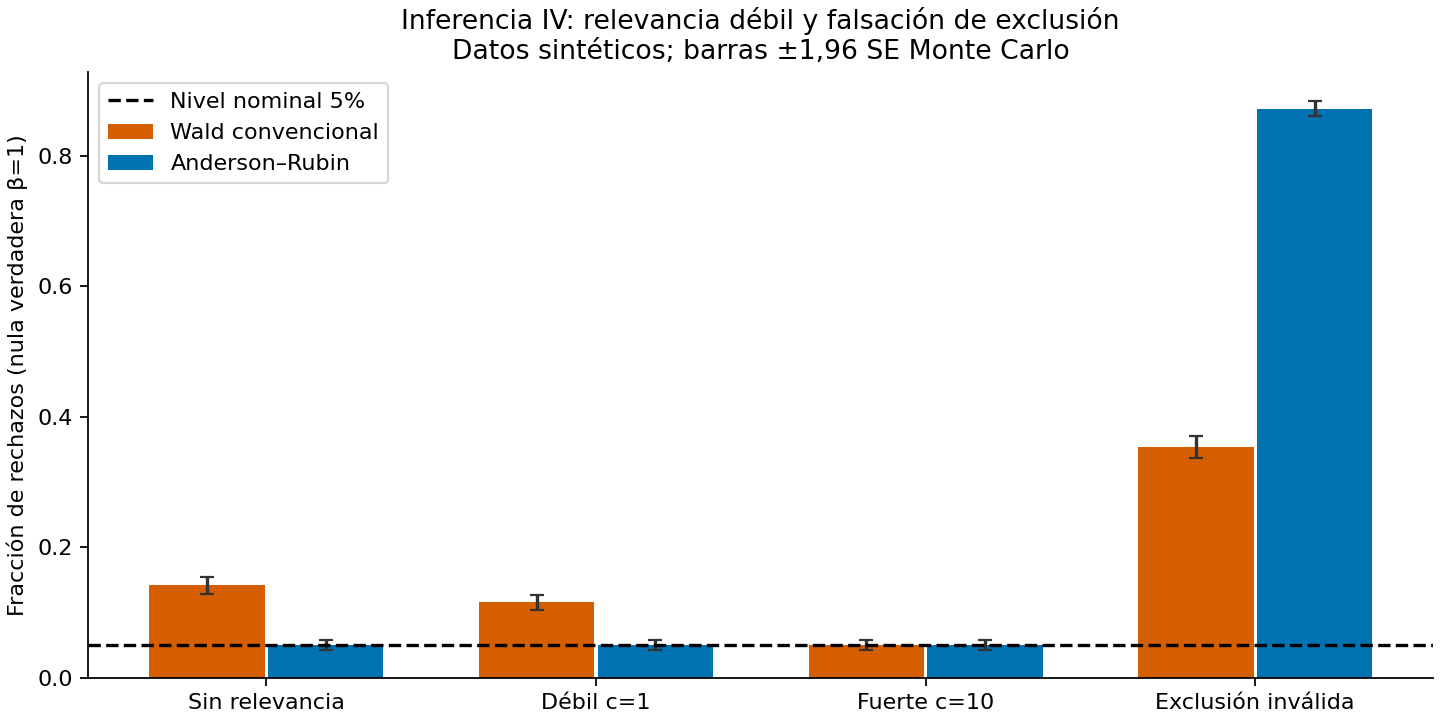

In [3]:
display(Image(filename=str(root / "results/rejection_rates.png")))

## Comprobación independiente y criterios
Comprobar un p-valor AR contra regresión reducida directa y contrastar hipótesis con resultados guardados. No convierte simulación en prueba general.

In [4]:
from scipy.stats import linregress
y, x, z = sample(12, 100, 1)
assert abs(ar_pvalue(y,x,z,1)-linregress(z,y-x).pvalue) < 1e-12
valid = result["summaries"][:3]
assert all(abs(s["ar_rejection"]-.05) <= .02 for s in valid)
weak = valid[1]
assert abs(weak["wald_rejection"]-.05)-abs(weak["ar_rejection"]-.05) >= .05
print("Criterios confirmados en esta corrida; no validación empírica.")

Criterios confirmados en esta corrida; no validación empírica.


## Conclusiones y límites
Preferir inferencia válida ante relevancia débil no resuelve identificación económica. Con instrumento válido fuerte la mejora en tamaño desaparece; con exclusión inválida el test AR también falla. No cubre poder, heteroscedasticidad, autocorrelación, clustering ni conjuntos invertidos no acotados/desconectados. S2 local; no elevar el programa. Ver informe y cinco referencias bibliográficas.

Ejecución: secuencial en IPython en proceso limpio, sin kernel Jupyter; outputs persistidos y errores abortan. El entorno restringido puede prohibir sockets de kernels.